## Apriori Algorithm – Association Rule Mining

Apriori is an unsupervised machine learning algorithm used to discover frequent itemsets and association rules in transactional datasets.

It identifies products that frequently occur together, helping uncover purchasing patterns.

### How It Works
1. Identifies frequent individual items.
2. Generates candidate itemsets with increasing numbers of items.
3. Removes itemsets that do not meet the minimum support threshold.
4. Generates association rules from the frequent itemsets.
5. Evaluates rules using metrics such as support, confidence, and lift.

### Key Concepts
- **Itemset:** A collection of one or more items.
- **Support:** How frequently an itemset appears in transactions.
- **Confidence:** How often a rule is correct when its antecedent occurs.
- **Lift:** Measures how strongly two itemsets are associated compared to random occurrence.
- **Minimum Support:** The minimum frequency required for an itemset to be considered frequent.

### Key Formulas

**Support:**

$$
Support(A)=\frac{Transactions\ containing\ A}{Total\ transactions}
$$

**Confidence:**

$$
Confidence(A\rightarrow B)=\frac{Support(A\cup B)}{Support(A)}
$$

**Lift:**

$$
Lift(A\rightarrow B)=\frac{Confidence(A\rightarrow B)}{Support(B)}
$$

### Advantages
- Easy to understand and interpret.
- Useful for market basket analysis.
- Reveals purchasing relationships between items.

### Limitations
- Can generate many candidate itemsets.
- May be computationally expensive on large datasets.
- Results depend on the selected support threshold.

In [75]:
%pip install mlxtend

Note: you may need to restart the kernel to use updated packages.


In [76]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder
import warnings
warnings.filterwarnings('ignore')

In [77]:
# load dataset 
df = pd.read_csv("../Datasets/Groceries_dataset.csv")
print(df.head())

   Member_number        Date   itemDescription
0           1808  21-07-2015    tropical fruit
1           2552  05-01-2015        whole milk
2           2300  19-09-2015         pip fruit
3           1187  12-12-2015  other vegetables
4           3037  01-02-2015        whole milk


In [78]:
# group Items by Transaction
basket = df.groupby(['Member_number', 'Date'])['itemDescription'].apply(list).reset_index()
transactions = basket['itemDescription'].tolist()
transactions

[['sausage', 'whole milk', 'semi-finished bread', 'yogurt'],
 ['whole milk', 'pastry', 'salty snack'],
 ['canned beer', 'misc. beverages'],
 ['sausage', 'hygiene articles'],
 ['soda', 'pickled vegetables'],
 ['frankfurter', 'curd'],
 ['sausage', 'whole milk', 'rolls/buns'],
 ['whole milk', 'soda'],
 ['beef', 'white bread'],
 ['frankfurter', 'soda', 'whipped/sour cream'],
 ['frozen vegetables', 'other vegetables'],
 ['butter', 'whole milk'],
 ['tropical fruit', 'sugar'],
 ['butter milk', 'specialty chocolate'],
 ['sausage', 'rolls/buns'],
 ['root vegetables', 'detergent'],
 ['frozen meals', 'dental care'],
 ['rolls/buns', 'rolls/buns'],
 ['dish cleaner', 'cling film/bags'],
 ['canned beer', 'frozen fish'],
 ['other vegetables', 'hygiene articles'],
 ['pip fruit', 'whole milk', 'tropical fruit'],
 ['rolls/buns', 'red/blush wine', 'chocolate'],
 ['other vegetables', 'shopping bags'],
 ['whole milk', 'chocolate', 'packaged fruit/vegetables', 'rolls/buns'],
 ['root vegetables', 'whole milk'

In [79]:
# convert to One-Hot Format
from mlxtend.preprocessing import TransactionEncoder
te= TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)
df_encoded = pd.DataFrame(te_array, columns=te.columns_)

In [80]:
# Apriori algorithm
from mlxtend.frequent_patterns import apriori
frequent_itemsets = apriori(df_encoded, min_support=0.01, use_colnames=True)
print("Total Frequent Itemsets:", frequent_itemsets.shape[0])

Total Frequent Itemsets: 69


In [81]:
# Association rules
from mlxtend.frequent_patterns import association_rules
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.1)
rules = rules[rules['antecedents'].apply(lambda x: len(x) >= 1) & rules['consequents'].apply(lambda x: len(x) >= 1)]
print("Association Rules:", rules.shape[0])
print(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(5))

Association Rules: 4
          antecedents   consequents   support  confidence      lift
0  (other vegetables)  (whole milk)  0.014837    0.121511  0.769430
1        (rolls/buns)  (whole milk)  0.013968    0.126974  0.804028
2              (soda)  (whole milk)  0.011629    0.119752  0.758296
3            (yogurt)  (whole milk)  0.011161    0.129961  0.822940


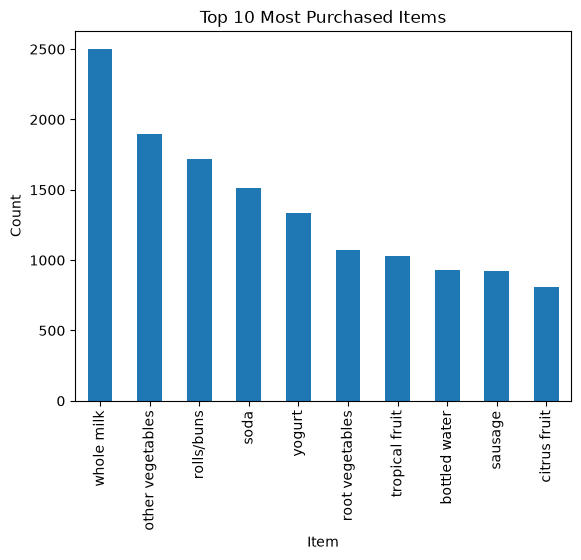

In [82]:
# most frequent items
import matplotlib.pyplot as plt
top_items = df['itemDescription'].value_counts().head(10)
top_items.plot(kind='bar', title='Top 10 Most Purchased Items')
plt.xlabel("Item")
plt.ylabel("Count")
plt.show()

In [83]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

## Retail dataset

In [84]:
retail_df = pd.read_csv("../Datasets/OnlineRetail.csv", encoding="ISO-8859-1")
print(retail_df.shape)
retail_df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [85]:
retail_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [86]:
retail_df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [87]:
retail_df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [88]:
retail_df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [89]:
# transaction data
retail_df['Description'].nunique()

4223

In [90]:
# no. of unique 
retail_df['InvoiceNo'].nunique()

25900

In [91]:
# most frequent purchased 
retail_df['Description'].value_counts().head(10)

Description
WHITE HANGING HEART T-LIGHT HOLDER    2369
REGENCY CAKESTAND 3 TIER              2200
JUMBO BAG RED RETROSPOT               2159
PARTY BUNTING                         1727
LUNCH BAG RED RETROSPOT               1638
ASSORTED COLOUR BIRD ORNAMENT         1501
SET OF 3 CAKE TINS PANTRY DESIGN      1473
PACK OF 72 RETROSPOT CAKE CASES       1385
LUNCH BAG  BLACK SKULL.               1350
NATURAL SLATE HEART CHALKBOARD        1280
Name: count, dtype: int64

In [92]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

mpl.rcParams['font.enable_last_resort'] = False
mpl.rcParams['font.family'] = 'DejaVu Sans'
mpl.rcParams['text.usetex'] = False
mpl.rcParams['axes.unicode_minus'] = False

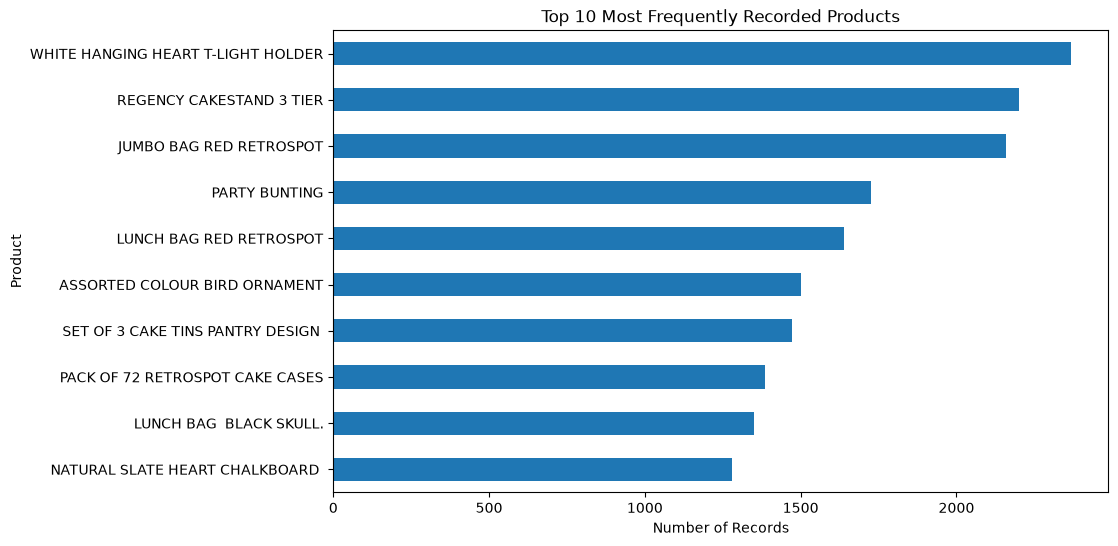

In [93]:
plt.figure(figsize=(10, 6))

retail_df['Description'].value_counts().head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Most Frequently Recorded Products')
plt.xlabel('Number of Records')
plt.ylabel('Product')
plt.show()

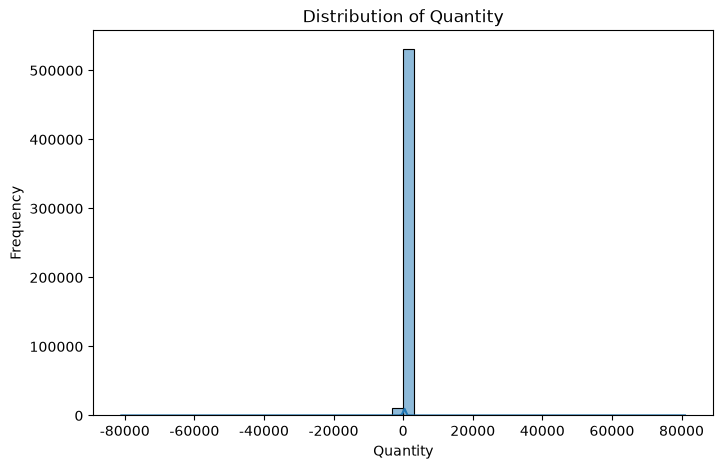

In [94]:
# quality distributions
plt.figure(figsize=(8, 5))

sns.histplot(retail_df['Quantity'], bins=50, kde=True)

plt.title('Distribution of Quantity')
plt.xlabel('Quantity')
plt.ylabel('Frequency')
plt.show()

In [100]:
# Preprocessing
online_df = retail_df.copy()

print(online_df.columns.tolist())
online_df = online_df.dropna(subset=['InvoiceNo', 'Description'])

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [101]:
online_df = online_df[
    ~online_df['InvoiceNo'].astype(str).str.startswith('C')
]

In [102]:
online_df = online_df[online_df['Quantity'] > 0]

In [103]:
online_df['Description'] = online_df['Description'].str.strip()

online_df = online_df[online_df['Description'] != '']

In [106]:
# transaction list
transaction = online_df.groupby('InvoiceNo')['Description'].apply(list)
transaction.head()

InvoiceNo
536365    [WHITE HANGING HEART T-LIGHT HOLDER, WHITE MET...
536366    [HAND WARMER UNION JACK, HAND WARMER RED POLKA...
536367    [ASSORTED COLOUR BIRD ORNAMENT, POPPY'S PLAYHO...
536368    [JAM MAKING SET WITH JARS, RED COAT RACK PARIS...
536369                           [BATH BUILDING BLOCK WORD]
Name: Description, dtype: object

In [107]:
print("Total transactions:", len(transactions))

Total transactions: 20136


In [108]:
transactions.iloc[0]

['WHITE HANGING HEART T-LIGHT HOLDER',
 'WHITE METAL LANTERN',
 'CREAM CUPID HEARTS COAT HANGER',
 'KNITTED UNION FLAG HOT WATER BOTTLE',
 'RED WOOLLY HOTTIE WHITE HEART.',
 'SET 7 BABUSHKA NESTING BOXES',
 'GLASS STAR FROSTED T-LIGHT HOLDER']

In [109]:
# initialize and fit encoder
transaction_encoder = TransactionEncoder()

te_array = transaction_encoder.fit(transactions).transform(transactions)

In [111]:
basket = pd.DataFrame(te_array,columns=transaction_encoder.columns_)
basket.head()

,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,...,returned,taig adjust,test,to push order througha s stock was,website fixed,wrongly coded 20713,wrongly coded 23343,wrongly marked,wrongly marked 23343,wrongly sold (22719) barcode
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [112]:
basket.sum().sort_values(ascending=False).head(10)

WHITE HANGING HEART T-LIGHT HOLDER    2260
JUMBO BAG RED RETROSPOT               2092
REGENCY CAKESTAND 3 TIER              1989
PARTY BUNTING                         1686
LUNCH BAG RED RETROSPOT               1564
ASSORTED COLOUR BIRD ORNAMENT         1455
SET OF 3 CAKE TINS PANTRY DESIGN      1385
PACK OF 72 RETROSPOT CAKE CASES       1320
LUNCH BAG  BLACK SKULL.               1273
NATURAL SLATE HEART CHALKBOARD        1249
dtype: int64

In [114]:
# frequent items
frequent_itemsets = apriori(basket,min_support=0.02,use_colnames=True)
frequent_itemsets.head(10)

,support,itemsets
0,0.023242,(3 STRIPEY MICE FELTCRAFT)
1,0.024037,(4 TRADITIONAL SPINNING TOPS)
2,0.047427,(6 RIBBONS RUSTIC CHARM)
3,0.021702,(60 CAKE CASES DOLLY GIRL DESIGN)
4,0.030691,(60 CAKE CASES VINTAGE CHRISTMAS)
5,0.041120,(60 TEATIME FAIRY CAKE CASES)
6,0.030542,(72 SWEETHEART FAIRY CAKE CASES)
7,0.021255,(ALARM CLOCK BAKELIKE CHOCOLATE)
8,0.048669,(ALARM CLOCK BAKELIKE GREEN)
9,0.028308,(ALARM CLOCK BAKELIKE IVORY)


In [116]:
frequent_itemsets.sort_values(by='support',ascending=False).head(10)

,support,itemsets
274,0.112237,(WHITE HANGING HEART T-LIGHT HOLDER)
102,0.103894,(JUMBO BAG RED RETROSPOT)
197,0.098778,(REGENCY CAKESTAND 3 TIER)
157,0.083731,(PARTY BUNTING)
127,0.077672,(LUNCH BAG RED RETROSPOT)
15,0.072259,(ASSORTED COLOUR BIRD ORNAMENT)
219,0.068782,(SET OF 3 CAKE TINS PANTRY DESIGN)
149,0.065554,(PACK OF 72 RETROSPOT CAKE CASES)
120,0.063220,(LUNCH BAG BLACK SKULL.)
139,0.062028,(NATURAL SLATE HEART CHALKBOARD)


In [117]:
print("Total frequent itemsets:", len(frequent_itemsets))

Total frequent itemsets: 376


In [118]:
rules = association_rules(frequent_itemsets,metric="confidence",min_threshold=0.5)
rules.head(10)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(60 TEATIME FAIRY CAKE CASES),(PACK OF 72 RETROSPOT CAKE CASES),0.041120,0.065554,0.022497,0.547101,8.345784,1.0,0.019801,2.063256,0.917924,0.267257,0.515329,0.445142
1,(ALARM CLOCK BAKELIKE PINK),(ALARM CLOCK BAKELIKE GREEN),0.038886,0.048669,0.020759,0.533844,10.968864,1.0,0.018866,2.040800,0.945603,0.310781,0.509996,0.480187
2,(ALARM CLOCK BAKELIKE GREEN),(ALARM CLOCK BAKELIKE RED),0.048669,0.052195,0.031784,0.653061,12.511932,1.0,0.029244,2.731908,0.967146,0.460101,0.633956,0.631003
3,(ALARM CLOCK BAKELIKE RED),(ALARM CLOCK BAKELIKE GREEN),0.052195,0.048669,0.031784,0.608944,12.511932,1.0,0.029244,2.432722,0.970744,0.460101,0.588938,0.631003
4,(ALARM CLOCK BAKELIKE PINK),(ALARM CLOCK BAKELIKE RED),0.038886,0.052195,0.023341,0.600255,11.500231,1.0,0.021312,2.371026,0.949986,0.344575,0.578242,0.523724
5,(CHARLOTTE BAG PINK POLKADOT),(CHARLOTTE BAG SUKI DESIGN),0.036899,0.043802,0.020362,0.551817,12.597944,1.0,0.018745,2.133499,0.955894,0.337449,0.531286,0.508335
6,(RED RETROSPOT CHARLOTTE BAG),(CHARLOTTE BAG PINK POLKADOT),0.051351,0.036899,0.025924,0.504836,13.681520,1.0,0.024029,1.945012,0.977083,0.415936,0.485864,0.603696
7,(CHARLOTTE BAG PINK POLKADOT),(RED RETROSPOT CHARLOTTE BAG),0.036899,0.051351,0.025924,0.702557,13.681520,1.0,0.024029,3.189350,0.962421,0.415936,0.686456,0.603696
8,(CHARLOTTE BAG SUKI DESIGN),(RED RETROSPOT CHARLOTTE BAG),0.043802,0.051351,0.025179,0.574830,11.194174,1.0,0.022930,2.231223,0.952384,0.359830,0.551815,0.532579
9,(STRAWBERRY CHARLOTTE BAG),(CHARLOTTE BAG SUKI DESIGN),0.035856,0.043802,0.020610,0.574792,13.122468,1.0,0.019039,2.248778,0.958150,0.349033,0.555314,0.522657


In [119]:
rules.sort_values(by='lift',ascending=False).head(10)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
51,"(GREEN REGENCY TEACUP AND SAUCER, ROSES REGENC...",(PINK REGENCY TEACUP AND SAUCER),0.038141,0.038041,0.026917,0.705729,18.551648,1.0,0.025466,3.268957,0.983612,0.546371,0.694092,0.706650
52,(PINK REGENCY TEACUP AND SAUCER),"(GREEN REGENCY TEACUP AND SAUCER, ROSES REGENC...",0.038041,0.038141,0.026917,0.707572,18.551648,1.0,0.025466,3.289215,0.983510,0.546371,0.695976,0.706650
50,"(PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY...",(GREEN REGENCY TEACUP AND SAUCER),0.029748,0.050407,0.026917,0.904841,17.950627,1.0,0.025417,9.979054,0.973243,0.505597,0.899790,0.719416
53,(GREEN REGENCY TEACUP AND SAUCER),"(PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY...",0.050407,0.029748,0.026917,0.533990,17.950627,1.0,0.025417,2.082042,0.994417,0.505597,0.519702,0.719416
18,(GREEN REGENCY TEACUP AND SAUCER),(PINK REGENCY TEACUP AND SAUCER),0.050407,0.038041,0.031436,0.623645,16.393893,1.0,0.029519,2.555990,0.988847,0.551394,0.608762,0.725008
17,(PINK REGENCY TEACUP AND SAUCER),(GREEN REGENCY TEACUP AND SAUCER),0.038041,0.050407,0.031436,0.826371,16.393893,1.0,0.029519,5.469083,0.976135,0.551394,0.817154,0.725008
49,"(PINK REGENCY TEACUP AND SAUCER, GREEN REGENCY...",(ROSES REGENCY TEACUP AND SAUCER),0.031436,0.052940,0.026917,0.856240,16.173782,1.0,0.025253,6.587791,0.968621,0.468453,0.848204,0.682341
54,(ROSES REGENCY TEACUP AND SAUCER),"(PINK REGENCY TEACUP AND SAUCER, GREEN REGENCY...",0.052940,0.031436,0.026917,0.508443,16.173782,1.0,0.025253,1.970399,0.990615,0.468453,0.492489,0.682341
15,(GARDENERS KNEELING PAD KEEP CALM),(GARDENERS KNEELING PAD CUP OF TEA),0.045342,0.037644,0.027116,0.598028,15.886413,1.0,0.025409,2.394090,0.981559,0.485333,0.582305,0.659173
16,(GARDENERS KNEELING PAD CUP OF TEA),(GARDENERS KNEELING PAD KEEP CALM),0.037644,0.045342,0.027116,0.720317,15.886413,1.0,0.025409,3.413354,0.973707,0.485333,0.707033,0.659173


In [120]:
rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10)

,antecedents,consequents,support,confidence,lift
0,(60 TEATIME FAIRY CAKE CASES),(PACK OF 72 RETROSPOT CAKE CASES),0.022497,0.547101,8.345784
1,(ALARM CLOCK BAKELIKE PINK),(ALARM CLOCK BAKELIKE GREEN),0.020759,0.533844,10.968864
2,(ALARM CLOCK BAKELIKE GREEN),(ALARM CLOCK BAKELIKE RED),0.031784,0.653061,12.511932
3,(ALARM CLOCK BAKELIKE RED),(ALARM CLOCK BAKELIKE GREEN),0.031784,0.608944,12.511932
4,(ALARM CLOCK BAKELIKE PINK),(ALARM CLOCK BAKELIKE RED),0.023341,0.600255,11.500231
5,(CHARLOTTE BAG PINK POLKADOT),(CHARLOTTE BAG SUKI DESIGN),0.020362,0.551817,12.597944
6,(RED RETROSPOT CHARLOTTE BAG),(CHARLOTTE BAG PINK POLKADOT),0.025924,0.504836,13.681520
7,(CHARLOTTE BAG PINK POLKADOT),(RED RETROSPOT CHARLOTTE BAG),0.025924,0.702557,13.681520
8,(CHARLOTTE BAG SUKI DESIGN),(RED RETROSPOT CHARLOTTE BAG),0.025179,0.574830,11.194174
9,(STRAWBERRY CHARLOTTE BAG),(CHARLOTTE BAG SUKI DESIGN),0.020610,0.574792,13.122468


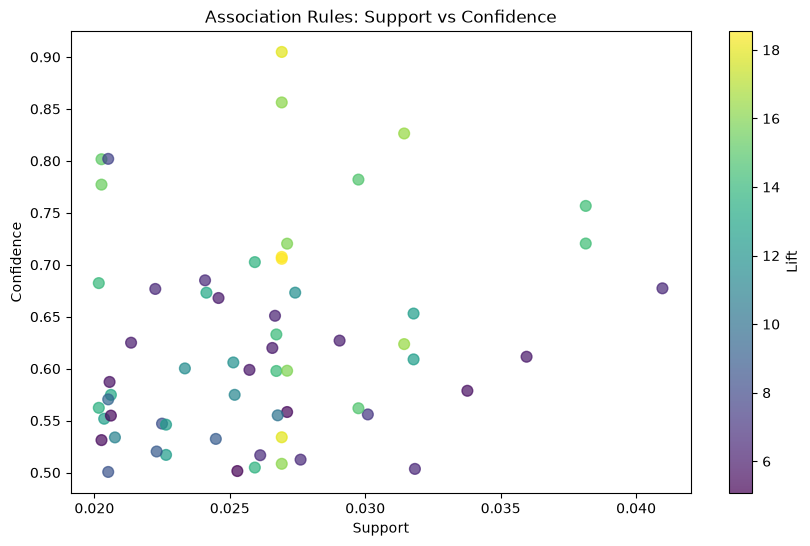

In [121]:
plt.figure(figsize=(10, 6))

scatter = plt.scatter(rules['support'],rules['confidence'],c=rules['lift'],cmap='viridis',s=60,alpha=0.7)

plt.colorbar(scatter, label='Lift')
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.title('Association Rules: Support vs Confidence')
plt.show()

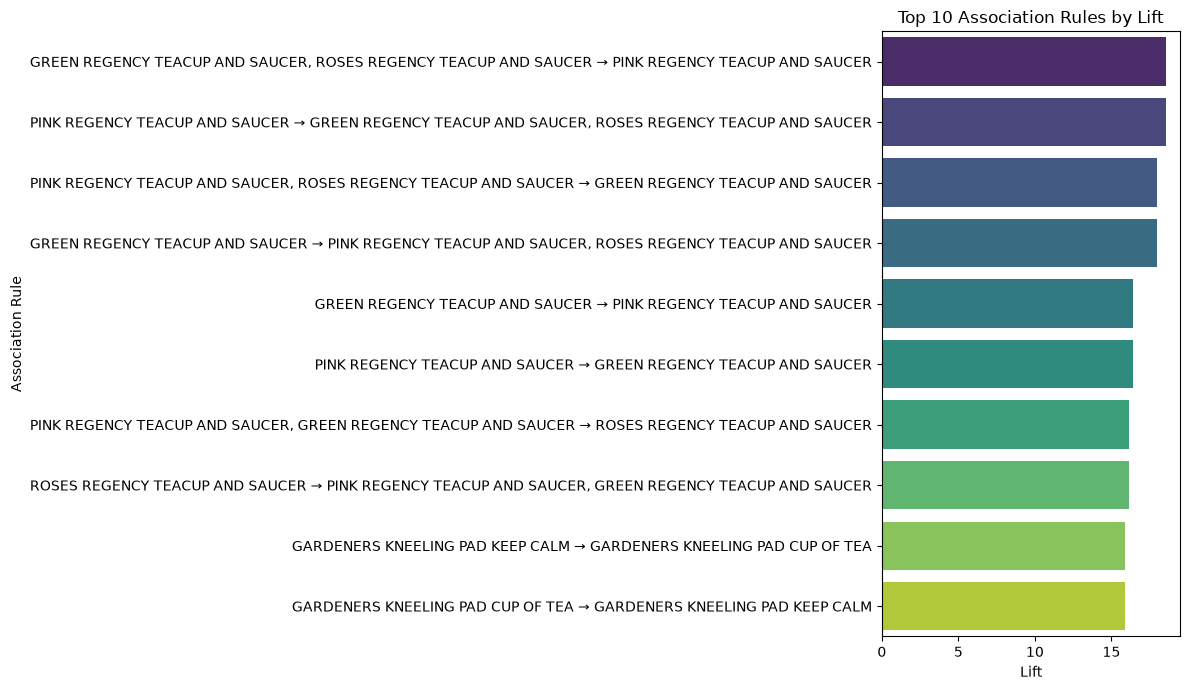

In [122]:
top_rules = rules.sort_values(by='lift',ascending=False).head(10).copy()

top_rules['Rule'] = top_rules.apply(
    lambda row: ', '.join(row['antecedents']) +
    ' → ' + ', '.join(row['consequents']),
    axis=1
)

plt.figure(figsize=(12, 7))
sns.barplot(data=top_rules,x='lift',y='Rule',hue='Rule',palette='viridis',legend=False)

plt.title('Top 10 Association Rules by Lift')
plt.xlabel('Lift')
plt.ylabel('Association Rule')
plt.tight_layout()
plt.show()

## Conclusion – Online retail Apriori Algorithm

The Apriori algorithm was applied to the Online Retail dataset to identify frequent product combinations and discover purchasing patterns.

The dataset was cleaned, grouped by invoice number, and transformed into a one-hot encoded transaction matrix before applying Apriori.

### Model Configuration
- Minimum support: 0.02
- Minimum confidence: 0.5
- Rule evaluation metric: Lift

### Key Findings
- Several products showed strong purchasing associations.
- Alarm Clock Bakelike products frequently appeared together.
- Charlotte Bag designs demonstrated particularly strong associations.
- The strongest displayed association had a lift of 13.68.

### Final Observation
Apriori successfully identified frequent itemsets and meaningful association rules in the retail transactions. These patterns can support market basket analysis, product recommendations, cross-selling, and product placement strategies.

Overall, the algorithm demonstrated how transactional data can be used to uncover relationships between products and understand customer purchasing behaviour.